In [6]:
import pandas as pd
import numpy as np

# පහළ 'car_price.csv' වෙනුවට ඔයා upload කරපු file එකේ හරි නම දාන්න
df = pd.read_csv('car_price_dataset.csv')

# 1. මුල් පේළි (rows) 5 බලාගැනීම
display(df.head())

# 2. Data වල තොරතුරු සහ Missing values බැලීම
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9788 entries, 0 to 9787
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      9788 non-null   int64  
 1   Brand           9788 non-null   object 
 2   Model           9788 non-null   object 
 3   YOM             9788 non-null   int64  
 4   Engine (cc)     9788 non-null   float64
 5   Gear            9788 non-null   object 
 6   Fuel Type       9788 non-null   object 
 7   Millage(KM)     9788 non-null   float64
 8   Town            9788 non-null   object 
 9   Date            9788 non-null   object 
 10  Leasing         9788 non-null   object 
 11  Condition       9788 non-null   object 
 12  AIR CONDITION   9788 non-null   object 
 13  POWER STEERING  9788 non-null   object 
 14  POWER MIRROR    9788 non-null   object 
 15  POWER WINDOW    9788 non-null   object 
 16  Price           9788 non-null   float64
dtypes: float64(3), int64(2), object(1

In [ ]:
# 1. අනවශ්‍ය columns ('Unnamed: 0', 'Date') අයින් කිරීම
df_clean = df.drop(columns=['Unnamed: 0', 'Date'])

# 2. Duplicate rows (එකම දත්තය නැවත තිබීම) පරීක්ෂා කර අයින් කිරීම
print(f"Duplicates ගණන: {df_clean.duplicated().sum()}")
df_clean = df_clean.drop_duplicates()
print(f"Duplicates අයින් කළාට පසු Rows ගණන: {len(df_clean)}")

# 3. Numerical columns වල සංඛ්‍යාත්මක විස්තර (Min, Max, Mean) බැලීම
print("\n--- Numerical Summary ---")
display(df_clean.describe())

# 4. Categorical columns වල unique values ගණන බැලීම
print("\n--- Unique Values in Categorical Columns ---")
cat_cols = df_clean.select_dtypes(include='object').columns
for col in cat_cols:
    print(f"{col}: {df_clean[col].nunique()} unique values -> {df_clean[col].unique()[:5]}")

Duplicates ගණන: 252
Duplicates අයින් කළාට පසු Rows ගණන: 9536

--- Numerical Summary ---


,YOM,Engine (cc),Millage(KM),Price
count,9536.000000,9536.000000,9536.000000,9536.000000
mean,2006.681208,1265.253230,201506.711409,53.480638
std,9.865689,403.610849,108522.577484,43.733002
min,1956.000000,573.000000,11000.000000,2.650000
25%,2001.000000,1000.000000,110000.000000,26.294595
50%,2009.000000,1300.000000,176000.000000,43.000000
75%,2015.000000,1500.000000,264000.000000,69.560417
max,2024.000000,4800.000000,759000.000000,790.000000



--- Unique Values in Categorical Columns ---
Brand: 50 unique values -> ['AUDI' 'AUSTIN' 'BAJAJ' 'BMW' 'BYD']
Model: 1555 unique values -> ['A1' 'A1 RS' 'A3' 'A3 S LINE' 'A3 S-LINE']
Gear: 2 unique values -> ['Automatic' 'Manual']
Fuel Type: 4 unique values -> ['Petrol' 'Diesel' 'Hybrid' 'Electric']
Town: 107 unique values -> ['Gampaha' 'Colombo' 'Dehiwala-Mount-Lavinia' 'Negombo' 'Matara']
Leasing: 2 unique values -> ['No Leasing' 'Ongoing Lease']
Condition: 2 unique values -> ['USED' 'NEW']
AIR CONDITION: 2 unique values -> ['Available' 'Not_Available']
POWER STEERING: 2 unique values -> ['Available' 'Not_Available']
POWER MIRROR: 2 unique values -> ['Available' 'Not_Available']
POWER WINDOW: 2 unique values -> ['Available' 'Not_Available']


In [ ]:
df_fe = df_clean.copy()

# 1. Feature Engineering: Vehicle Age සෑදීම (2025 dataset එකක් නිසා 2025න් අඩු කරමු)
df_fe['Vehicle_Age'] = 2025 - df_fe['YOM']
df_fe = df_fe.drop(columns=['YOM']) # YOM වෙනුවට Vehicle_Age තියෙන නිසා YOM අයින් කරමු

# 2. Feature Engineering: Options_Count සෑදීම (Available options ගණන එකතු කිරීම)
option_cols = ['AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']
for col in option_cols:
    df_fe[col] = df_fe[col].map({'Available': 1, 'Not_Available': 0})

df_fe['Options_Count'] = df_fe[option_cols].sum(axis=1)
df_fe = df_fe.drop(columns=option_cols) # තනි තනි option columns අයින් කරමු

# 3. Binary Columns (වර්ග 2ක් පමණක් ඇති ඒවා) 0 සහ 1 බවට හැරවීම
df_fe['Gear'] = df_fe['Gear'].map({'Automatic': 1, 'Manual': 0})
df_fe['Condition'] = df_fe['Condition'].map({'NEW': 1, 'USED': 0})
df_fe['Leasing'] = df_fe['Leasing'].map({'Ongoing Lease': 1, 'No Leasing': 0})

# 4. Model සහ Town columns වල Text පිරිසිදු කිරීම (Clean text)
df_fe['Model'] = df_fe['Model'].str.upper().str.replace('-', ' ').str.strip()
df_fe['Town'] = df_fe['Town'].str.upper().str.strip()

# 5. Rare Categories Handle කිරීම (15 පාරකට වඩා අඩුවෙන් ඇති Models/Towns 'OTHER' බවට හැරවීම)
for col in ['Brand', 'Model', 'Town']:
    counts = df_fe[col].value_counts()
    rare_items = counts[counts < 15].index
    df_fe[col] = df_fe[col].replace(rare_items, 'OTHER')

print("Clean කිරීමෙන් පසු Unique Values ගණන:")
print(f"Brand: {df_fe['Brand'].nunique()}, Model: {df_fe['Model'].nunique()}, Town: {df_fe['Town'].nunique()}")

# 6. One-Hot Encoding (ඉතිරි Categorical columns numbers බවට හැරවීම)
df_encoded = pd.get_dummies(df_fe, columns=['Brand', 'Model', 'Fuel Type', 'Town'], drop_first=True)

print(f"\nඅවසාන Dataset Shape (Rows, Columns): {df_encoded.shape}")
display(df_encoded.head(3))

Clean කිරීමෙන් පසු Unique Values ගණන:
Brand: 32, Model: 134, Town: 80

අවසාන Dataset Shape (Rows, Columns): (9536, 254)


,Engine (cc),Gear,Millage(KM),Leasing,Condition,Price,Vehicle_Age,Options_Count,Brand_AUSTIN,Brand_BMW,...,Town_PUTTALAM,Town_RAGAMA,Town_RATNAPURA,Town_TANGALLE,Town_TRINCOMALEE,Town_VAVUNIYA,Town_VEYANGODA,Town_WATTALA,Town_WELIMADA,Town_WENNAPPUWA
0,990.0,1,99000.0,0,0,100.0,9,4,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1000.0,1,88000.0,0,0,97.0,8,4,False,False,...,False,False,False,False,False,False,False,False,False,False
2,1000.0,1,77000.0,0,0,98.5,7,4,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Features (X) සහ Target (y - Price) වෙන් කිරීම
X = df_encoded.drop(columns=['Price'])
y = df_encoded['Price']

# 2. Data 80% Training සහ 20% Testing ලෙස බෙදීම
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}\n")

# --- Model 1: Linear Regression ---
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("--- 1. Linear Regression Results ---")
print(f"R2 Score (Accuracy): {r2_score(y_test, lr_preds):.4f}")
print(f"MAE (සාමාන්‍ය දෝෂය - ලක්ෂ වලින්): {mean_absolute_error(y_test, lr_preds):.2f} Lakhs\n")

# --- Model 2: Random Forest Regressor ---
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("--- 2. Random Forest Results ---")
print(f"R2 Score (Accuracy): {r2_score(y_test, rf_preds):.4f}")
print(f"MAE (සාමාන්‍ය දෝෂය - ලක්ෂ වලින්): {mean_absolute_error(y_test, rf_preds):.2f} Lakhs")

Training samples: 7628, Testing samples: 1908

--- 1. Linear Regression Results ---
R2 Score (Accuracy): 0.7551
MAE (සාමාන්‍ය දෝෂය - ලක්ෂ වලින්): 11.13 Lakhs

--- 2. Random Forest Results ---
R2 Score (Accuracy): 0.9044
MAE (සාමාන්‍ය දෝෂය - ලක්ෂ වලින්): 5.72 Lakhs


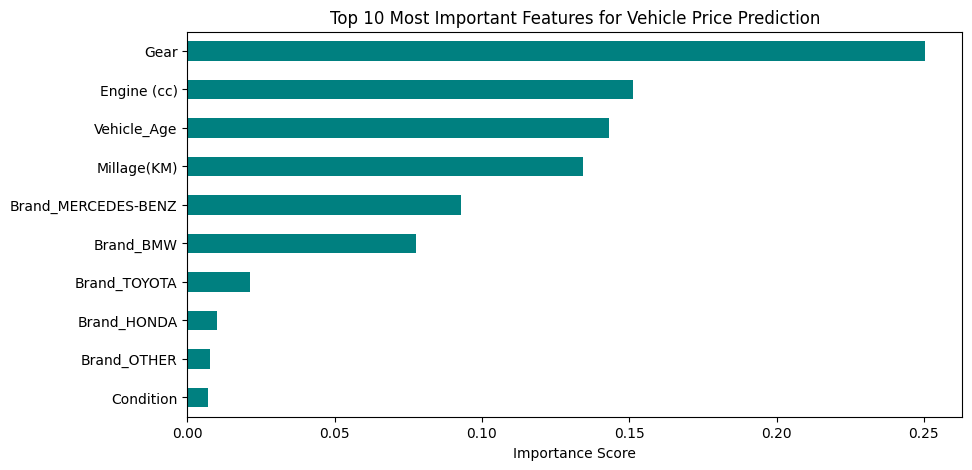

Model සහ Columns සාර්ථකව Save වුණා!

Predicted Price (2018 Toyota Axio): රු. ලක්ෂ 135.81


In [ ]:
import matplotlib.pyplot as plt
import joblib

# 1. වැදගත්ම Features (Top 10 Feature Importances) බැලීම
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_10_features = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top_10_features.plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title('Top 10 Most Important Features for Vehicle Price Prediction')
plt.xlabel('Importance Score')
plt.show()

# 2. අපි හදපු Model එක සහ Column names save කරගැනීම (Web App එකක් හදන්න පාවිච්චි කරන්න)
joblib.dump(rf_model, 'sl_vehicle_price_model.pkl')
joblib.dump(list(X.columns), 'model_columns.pkl')
print("Model සහ Columns සාර්ථකව Save වුණා!")

# 3. Real-world Test එකක්: අලුත් වාහනයක මිල Predict කර බැලීම
def predict_price(brand, model_name, yom, engine_cc, gear, fuel_type, mileage, town, leasing='No Leasing', condition='USED', options_count=4):
    # Input data සකස් කිරීම
    input_data = pd.DataFrame(columns=X.columns)
    input_data.loc[0] = 0 # මුලින් ඔක්කොම 0 කරනවා

    input_data['Engine (cc)'] = engine_cc
    input_data['Gear'] = 1 if gear == 'Automatic' else 0
    input_data['Millage(KM)'] = mileage
    input_data['Leasing'] = 1 if leasing == 'Ongoing Lease' else 0
    input_data['Condition'] = 1 if condition == 'NEW' else 0
    input_data['Vehicle_Age'] = 2025 - yom
    input_data['Options_Count'] = options_count

    # One-hot encoded columns 1 කිරීම (තිබේ නම්)
    for col_name in [f"Brand_{brand.upper()}", f"Model_{model_name.upper()}", f"Fuel Type_{fuel_type}", f"Town_{town.upper()}"]:
        if col_name in input_data.columns:
            input_data[col_name] = 1

    predicted_price = rf_model.predict(input_data)[0]
    return round(predicted_price, 2)

# උදාහරණයක්: 2018 Toyota Axio (1500cc, Hybrid, 85,000km, Colombo)
sample_price = predict_price('TOYOTA', 'AXIO', 2018, 1500, 'Automatic', 'Hybrid', 85000, 'COLOMBO')
print(f"\nPredicted Price (2018 Toyota Axio): රු. ලක්ෂ {sample_price}")

In [7]:
import joblib
import os
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# 1. File size එක අඩු කරන්න max_depth=20 සහ compress=3 දාලා අලුතින් model එක හදමු
rf_model_light = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
rf_model_light.fit(X_train, y_train)

print(f"New R2 Score: {r2_score(y_test, rf_model_light.predict(X_test)):.4f}")

# 2. Compress=3 දාලා save කරමු (Size එක 10x විතර අඩු වෙනවා!)
joblib.dump(rf_model_light, 'sl_vehicle_price_model.pkl', compress=3)
joblib.dump(list(X.columns), 'model_columns.pkl')

size_mb = os.path.getsize('sl_vehicle_price_model.pkl') / (1024 * 1024)
print(f"අලුත් Model File Size එක: {size_mb:.2f} MB")

New R2 Score: 0.9015
අලුත් Model File Size එක: 6.72 MB


In [8]:
from google.colab import drive
drive.mount('/content/drive')

!cp sl_vehicle_price_model.pkl /content/drive/MyDrive/
!cp model_columns.pkl /content/drive/MyDrive/
print("Files දෙකම ඔයාගේ Google Drive එකේ My Drive වලට copy වුණා!")

MessageError: Error: credential propagation was unsuccessful

In [9]:
from google.colab import files

files.download('sl_vehicle_price_model.pkl')
files.download('model_columns.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>